In [3]:
#Loads and spilits the data

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

df = pd.read_csv("updated_dataset.csv")
X = df.drop(columns="Survived")
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(712, 16) (179, 16)


Train and evaluate six models. Each model is scored on accuracy, precision, recall and F1-score using the test set, plus 5-fold cross-validation. The Decision Tree is tried with three depths on purpose, to show underfitting (depth 1), overfitting (no limit), and an improved version (depth 3)

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree (depth 1)": DecisionTreeClassifier(max_depth=1, random_state=42),
    "Decision Tree (no limit)": DecisionTreeClassifier(random_state=42),
    "Decision Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
fitted = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    y_pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "CV Accuracy": cross_val_score(model, X_train, y_train, cv=cv).mean(),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)

# Gap between training and test accuracy: a big gap means overfitting
results["Train-Test Gap"] = (results["Train Accuracy"] - results["Test Accuracy"]).round(3)
results

,Train Accuracy,CV Accuracy,Test Accuracy,Precision,Recall,F1-score,Train-Test Gap
Model,,,,,,,
Logistic Regression,0.826,0.820,0.832,0.810,0.739,0.773,-0.006
KNN (k=5),0.862,0.810,0.816,0.790,0.710,0.748,0.046
Decision Tree (depth 1),0.785,0.780,0.771,0.689,0.739,0.713,0.014
Decision Tree (no limit),0.983,0.799,0.793,0.742,0.710,0.726,0.190
Decision Tree (depth 3),0.843,0.826,0.816,0.750,0.783,0.766,0.027
Random Forest,0.983,0.801,0.816,0.773,0.739,0.756,0.167


Detailed report for the best model. The best model is chosen by F1-score, because it balances catching survivors (recall) with not raising false alarms (precision).

python$0

Best model: Logistic Regression
              precision    recall  f1-score   support

        Died       0.84      0.89      0.87       110
    Survived       0.81      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



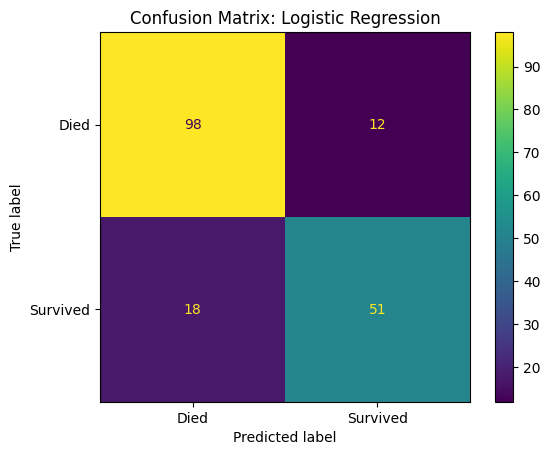

In [6]:
best_name = results["F1-score"].idxmax()
print("Best model:", best_name)
print(classification_report(y_test, fitted[best_name].predict(X_test),
                            target_names=["Died", "Survived"]))

ConfusionMatrixDisplay.from_estimator(
    fitted[best_name], X_test, y_test, display_labels=["Died", "Survived"])
plt.title(f"Confusion Matrix: {best_name}")
plt.savefig("confusion_matrix.png")
plt.show()

 Performance comparison chart. The chart compares the models side by side on the main test metrics.$0

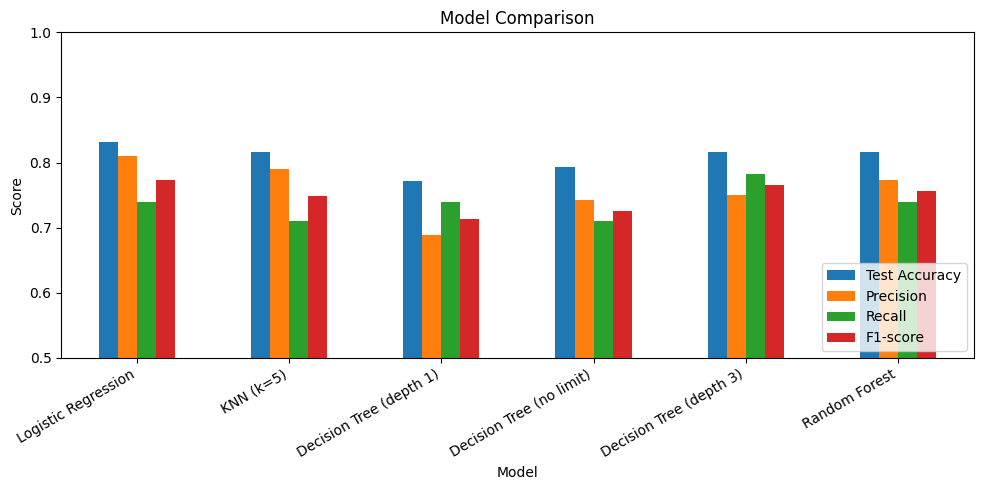

In [7]:
results[["Test Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

Saves the result

In [8]:
results.to_csv("performance_comparison.csv")

from google.colab import files
files.download("performance_comparison.csv")
files.download("model_comparison.png")
files.download("confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>